# GitSkills — data analysis

Uses the CSV files built by `data_cleaning.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

skills = pd.read_csv(DATA_DIR / "skills_copied.csv")
repos = pd.read_csv(DATA_DIR / "repos_clean.csv")
adoptions = pd.read_csv(DATA_DIR / "adoptions.csv")

## RQ1 — Do copied skills cross language boundaries?

We keep skills copied by at least 2 eligible owners, with one row per skill and owner. If an
owner has the skill in several repositories, we keep their most frequent language.

Each skill is then classified as:

- `siloed`: all owners use the same language
- `cross_language`: several languages, same ecosystem (ex: TypeScript and JavaScript)
- `cross_ecosystem`: several ecosystems (ex: Python and Rust)

In [2]:
rq1_ids = skills.loc[skills["n_owners_eligible"] >= 2, "skill_id"]
eligible_repos = repos.loc[repos["eligible"] == 1, ["repo_id", "owner", "language", "ecosystem"]]

owner_adoptions = (adoptions[adoptions["skill_id"].isin(rq1_ids)]
                   .merge(eligible_repos, on="repo_id")
                   .groupby(["skill_id", "owner", "language", "ecosystem"]).size().rename("n")
                   .reset_index()
                   .sort_values("n", ascending=False, kind="stable")
                   .drop_duplicates(["skill_id", "owner"]))

rq1 = owner_adoptions.groupby("skill_id").agg(
    n_owners=("owner", "size"), n_languages=("language", "nunique"),
    n_ecosystems=("ecosystem", "nunique"))
rq1["spread_class"] = "siloed"
rq1.loc[rq1["n_languages"] > 1, "spread_class"] = "cross_language"
rq1.loc[rq1["n_ecosystems"] > 1, "spread_class"] = "cross_ecosystem"
rq1["adopters"] = pd.cut(rq1["n_owners"], [1, 2, 5, 20, np.inf], labels=["2", "3-5", "6-20", ">20"])

print(f"{len(rq1):,} skills")
pd.crosstab(rq1["adopters"], rq1["spread_class"], normalize="index", margins=True).round(3)

67,103 skills


spread_class,cross_ecosystem,cross_language,siloed
adopters,,,
2,0.360,0.051,0.589
3-5,0.575,0.071,0.354
6-20,0.797,0.044,0.160
>20,0.988,0.007,0.006
All,0.522,0.054,0.424


### Comparison with chance

Most owners use JavaScript/TypeScript or Python, so even two random owners are often in
different ecosystems. To know if the observed crossing rate is high or low, we compare it to
what we would see if language played no role: we shuffle the ecosystems of the skill/owner
rows at random and recompute the rate, 1,000 times.

If the observed rate is below the expected one, skills tend to stay within their ecosystem.

In [20]:
N_PERMUTATIONS = 1000
rng = np.random.default_rng(42)

skill_codes, _ = pd.factorize(owner_adoptions["skill_id"])
ecosystem_codes, _ = pd.factorize(owner_adoptions["ecosystem"])
adopters = rq1["adopters"].reindex(owner_adoptions["skill_id"].unique()).to_numpy()


def crossing_rate(ecosystem):
    # Share of skills found in more than one ecosystem, per adopters group and overall
    crosses = pd.Series(ecosystem).groupby(skill_codes).nunique() > 1
    rates = crosses.groupby(adopters, observed=True).mean()
    rates["all"] = crosses.mean()
    return rates


observed = crossing_rate(ecosystem_codes)
expected = pd.concat([crossing_rate(rng.permutation(ecosystem_codes))
                      for _ in range(N_PERMUTATIONS)], axis=1)

results = pd.DataFrame({
    "observed": observed,
    "expected": expected.mean(axis=1),
    "p_value": ((expected.T <= observed).sum() + 1) / (N_PERMUTATIONS + 1),
}).round(3).rename_axis("adopters").reset_index()
results

,adopters,observed,expected,p_value
0,2,0.360,0.681,0.001
1,3-5,0.575,0.913,0.001
2,6-20,0.797,0.997,0.001
3,>20,0.988,1.000,0.001
4,all,0.522,0.817,0.001


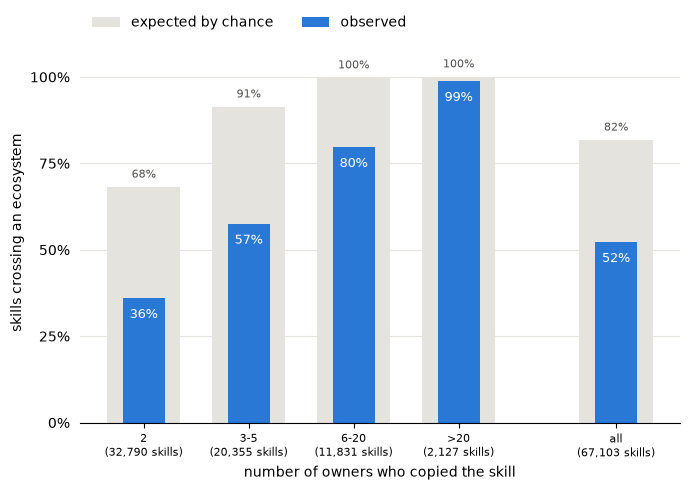

In [18]:
n_skills = list(rq1["adopters"].value_counts().sort_index()) + [len(rq1)]
labels = [f"{group}\n({n:,} skills)" for group, n in zip(results.index, n_skills)]
x = np.array([0, 1, 2, 3, 4.5])  # small gap before "all"

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x, results["expected"], width=0.7, color="#e4e3de", label="expected by chance")
ax.bar(x, results["observed"], width=0.4, color="#2a78d6", label="observed")
for xi, obs, exp in zip(x, results["observed"], results["expected"]):
    ax.text(xi, obs - 0.03, f"{obs:.0%}", ha="center", va="top", fontsize=9, color="white")
    ax.text(xi, exp + 0.02, f"{exp:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")

ax.set_xticks(x, labels, fontsize=8)
ax.set_xlabel("number of owners who copied the skill")
ax.set_ylabel("skills crossing an ecosystem")
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.grid(True, color="#e4e3de", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_ecosystem_crossing.pdf")
plt.show()

### Which ecosystems share skills?

For each skill, every pair of its owners gives a pair of ecosystems. We count these pairs
(weighted by 1 / (number of owners − 1) so that very popular skills do not dominate) and
divide by the count expected if owners were paired at random. Above 1 means the two ecosystems
share more skills than chance. On the other side, below 1 mean less. Only the 12 largest ecosystems are shown.

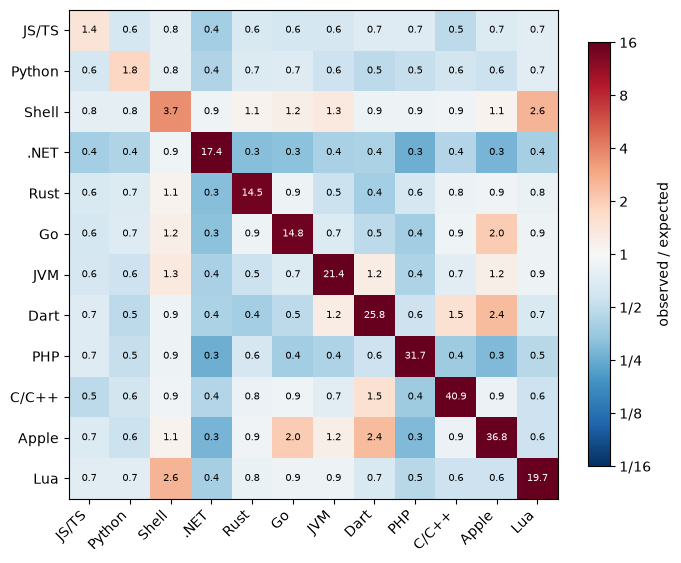

In [5]:
counts = pd.crosstab(owner_adoptions["skill_id"], owner_adoptions["ecosystem"])
C = counts.to_numpy()
weighted = C / (C.sum(axis=1, keepdims=True) - 1)

pairs = weighted.T @ C - np.diag(weighted.sum(axis=0))
totals = C.sum(axis=0)
ratio = pd.DataFrame(pairs / np.outer(totals, totals) * totals.sum(),
                     index=counts.columns, columns=counts.columns)

top = owner_adoptions["ecosystem"].value_counts().index[:12]
ratio = ratio.loc[top, top]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-4, vmax=4)
for i in range(len(top)):
    for j in range(len(top)):
        color = "white" if ratio.iat[i, j] > 6 else "black"
        ax.text(j, i, f"{ratio.iat[i, j]:.1f}", ha="center", va="center", fontsize=7, color=color)
ax.set_xticks(range(len(top)), top, rotation=45, ha="right")
ax.set_yticks(range(len(top)), top)
bar = fig.colorbar(im, ax=ax, shrink=0.8, ticks=range(-4, 5))
bar.ax.set_yticklabels(["1/16", "1/8", "1/4", "1/2", "1", "2", "4", "8", "16"])
bar.set_label("observed / expected")
fig.tight_layout()
fig.savefig(FIG_DIR / "rq1_ecosystem_heatmap.pdf")
plt.show()

Small ecosystems get large ratios easily, so we also look at the plain share of an
ecosystem's co-adopters that are in the same ecosystem, compared to its share of owners.

In [6]:
pd.DataFrame({
    "share_of_owners": totals / totals.sum(),
    "same_ecosystem_share": np.diag(pairs) / totals,
}, index=counts.columns).loc[top].round(3)

,share_of_owners,same_ecosystem_share
ecosystem,,
JS/TS,0.457,0.658
Python,0.324,0.578
Shell,0.057,0.207
.NET,0.032,0.554
Rust,0.023,0.329
Go,0.022,0.326
JVM,0.017,0.362
Dart,0.014,0.357
PHP,0.013,0.396
